# Eigenzeit: Referenz, Schätzung und Unsicherheit
**X6 Spectral Astrolabium · Eigenzeit-Labor 1.0 · 17. Oktober 2026**

Wie viel lässt sich aus der Zahl der Ereignisse zwischen zwei Endpunkten über deren Eigenzeit erfahren?
Dieses eigenständig ausführbare Notebook erzeugt ein bekanntes flaches Raumzeitmodell,
schätzt die Eigenzeit und zeigt den Unterschied zwischen einem einzelnen Ergebnis und
der Zuverlässigkeit eines statistischen Verfahrens.

**Start:** Python 3.12 und die Pakete aus `requirements.txt` installieren, die Datei in Jupyter
öffnen und **Kernel neu starten → Alle Zellen ausführen** wählen. Kein Repository-Checkout,
Netzwerkzugriff oder externer Datensatz ist für die Berechnung erforderlich.
Ändere danach nur die Parameterzelle und führe wieder alle folgenden Zellen aus.

- [Interaktiver Demonstrator](https://thomasmgfeller.github.io/x6-spectral-astrolabium/app/proper-time.html)
- [Veröffentlichter Gültigkeitsvertrag](https://github.com/thomasmgfeller/x6-spectral-astrolabium/blob/abf1423c985606f5c514ea1bfd2aa48a260ad2bf/research/lorentz_proper_time_domain/README.md)
- [NIST: exakte Binomial-Konfidenzgrenzen](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/exacbici.htm)

Dies ist eine ausführbare Erläuterung der bestehenden Referenz, keine neue wissenschaftliche Qualifikation.
Die gespeicherten Ausgaben sind ein Beispiel; eigene Parameter erzeugen neue Demonstrationsdaten.

## 1. Was wird vorausgesetzt?

Wir kennen die flache Minkowski-Geometrie, ihre Raumzeitdimension $d$ und die äussere
Zeitdauer $T$. In Einheiten $c=1$ betrachten wir den Diamanten
$D=\{(t,\mathbf x): |t|+\|\mathbf x\|<1/2\}$ in **normierten Koordinaten**.
Die beiden vorab festgelegten Endereignisse liegen bei
$p=(-\theta/2,0,\ldots,0)$ und $q=(\theta/2,0,\ldots,0)$.
Die wahre Eigenzeit beträgt $\tau=T\theta$.

Wir ziehen genau $m$ unabhängige, gleichmässig im Raumzeitvolumen verteilte Hintergrundpunkte.
Die Endpunkte gehören nicht zu diesen $m$ Punkten. Das gesamte innere Intervall liegt in $D$.
Der Simulator kennt $\theta$; die Schätzfunktion erhält nur $K,m,d,\alpha,T$.

Dies ist ein Modell mit **fester Gesamtzahl**, auch als homogene Poisson-Beprobung bedingt auf
die Gesamtzahl interpretierbar. Ein unbedingtes Poisson-Experiment mit bekannter Intensität
hätte eine andere Zähl-Likelihood. Die beiden Versuche werden hier nicht vermischt.

Geschätzt wird der maximale Eigenzeitabstand zwischen den Endereignissen, hier entlang der
geraden zeitartigen Verbindung; nicht die Eigenzeit einer beliebig beschleunigten Weltlinie.

In [1]:
import sys, json, platform
from pathlib import Path
import numpy as np
import scipy
from scipy.special import betaincinv
from scipy.stats import binom, beta
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__}
print(json.dumps(VERSIONS, indent=2))

{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "scipy": "1.17.0",
  "matplotlib": "3.10.8"
}


In [2]:
# PARAMETERZELLE: Danach alle folgenden Zellen erneut ausführen.
D = 4                 # Raumzeitdimension: 2, 3 oder 4
M = 1024              # Festes Hintergrundbudget: 1 ... 16384
THETA = 0.50          # Wahre normierte Eigenzeit: 0 < theta < 1
T = 1.0               # Extern vorgegebener Zeitmassstab (beliebige Einheit)
ALPHA = 0.05          # Festes 95%-Konfidenzverfahren
SEED = 20261017
REPEATS = 2000        # Zahl unabhängiger Wiederholungen; vor der Ziehung festlegen

assert D in (2, 3, 4) and isinstance(M, int) and 1 <= M <= 16384
assert 0 < THETA < 1 and np.isfinite(T) and T > 0 and ALPHA == .05
assert isinstance(SEED, int) and 0 <= SEED < 2**32
assert isinstance(REPEATS, int) and 40 <= REPEATS <= 100000
TRUTH = T * THETA
print(f'd={D}, m={M}, theta={THETA}, T={T}; wahre Eigenzeit = {TRUTH}')

d=4, m=1024, theta=0.5, T=1.0; wahre Eigenzeit = 0.5


## 2. Aus Volumen wird eine Zählwahrscheinlichkeit

Für einen flachen $d$-dimensionalen Diamanten gilt
$V_d(s)=c_ds^d$ mit $c_d=\omega_{d-1}/(d2^{d-1})$; insbesondere $c_4=\pi/24$.
Der Anteil des inneren Volumens ist daher $a=\theta^d$.

$$K\sim\mathrm{Binomial}(m,a),\qquad \widehat\tau=T(K/m)^{1/d}.$$

Die Wurzel ist konkav: Obwohl $K/m$ erwartungstreu für $a$ ist, ist die Wurzelschätzung
im Allgemeinen nach unten verzerrt. Clopper–Pearson-Grenzen für $a$ werden monoton
in Zeitgrenzen umgerechnet. Bei $K=0$ ist die obere Grenze **positiv**.

Die folgende Funktion kennt weder die Koordinaten noch die wahre Eigenzeit.

In [3]:
def infer(k, m, d, alpha=.05, T=1.0):
    if not (type(m) is int and 1 <= m <= 16384 and type(k) is int and 0 <= k <= m):
        raise ValueError('Ganzzahlige Zählungen mit 0 <= K <= m erforderlich')
    if d not in (2, 3, 4) or not (0 < alpha < 1 and np.isfinite(T) and T > 0):
        raise ValueError('Ungültige Dimension, alpha oder Zeitkalibrierung')
    low = 0.0 if k == 0 else float(betaincinv(k, m-k+1, alpha/2))
    high = 1.0 if k == m else float(betaincinv(k+1, m-k, 1-alpha/2))
    return {'k': k, 'm': m, 'theta_hat': (k/m)**(1/d),
            'estimate': T*(k/m)**(1/d), 'lower': T*low**(1/d),
            'upper': T*high**(1/d), 'a_low': low, 'a_high': high}

def all_limits(m, d, alpha=.05):
    ks = np.arange(m+1)
    low, high = np.zeros(m+1), np.ones(m+1)
    low[1:] = betaincinv(ks[1:], m-ks[1:]+1, alpha/2)
    high[:-1] = betaincinv(ks[:-1]+1, m-ks[:-1], 1-alpha/2)
    return low, high, low**(1/d), high**(1/d)

assert infer(0, M, D)['upper'] > 0
assert infer(M, M, D)['upper'] == 1
print('Leeres Intervall:', infer(0, M, D, ALPHA, T))

Leeres Intervall: {'k': 0, 'm': 1024, 'theta_hat': 0.0, 'estimate': 0.0, 'lower': 0.0, 'upper': 0.24487988997540017, 'a_low': 0.0, 'a_high': 0.003595940406834479}


## 3. Eine echte Punktwolke im Diamanten

Gleichmässige Zeitkoordinaten wären **keine** uniforme Volumenbeprobung.
Wir ziehen die Zeitscheiben-Halbbreite $A=U^{1/d}/2$, ein unabhängiges Vorzeichen
für $t=\pm(1/2-A)$ und einen uniformen Punkt in der räumlichen $(d-1)$-Kugel mit Radius $A$.
Gezählt wird mit allen räumlichen Koordinaten, nicht anhand der zweidimensionalen Projektion.

In [4]:
def sample_diamond(rng, m, d):
    A = .5 * rng.random(m)**(1/d)
    time = np.where(rng.integers(0, 2, m) == 0, -1.0, 1.0) * (.5-A)
    direction = rng.normal(size=(m, d-1))
    norm = np.linalg.norm(direction, axis=1)
    if np.any(norm == 0):
        raise ArithmeticError('Nullrichtung: keine stille Neuziehung')
    radius = A * rng.random(m)**(1/(d-1))
    return np.column_stack((time, direction*(radius/norm)[:, None]))

# Getrennte Streams für Geometrie und Wiederholungen.
streams = np.random.SeedSequence(SEED).spawn(2)
points = sample_diamond(np.random.default_rng(streams[0]), M, D)
inside = np.abs(points[:, 0]) + np.linalg.norm(points[:, 1:], axis=1) < THETA/2
K = int(inside.sum())
result = infer(K, M, D, ALPHA, T)
assert np.all(np.abs(points[:, 0]) + np.linalg.norm(points[:, 1:], axis=1) < .5)
print(f'K={K} von m={M}; geschätzte Eigenzeit={result["estimate"]:.6f}')
print(f'95%-Intervall: [{result["lower"]:.6f}, {result["upper"]:.6f}]')
print(f'Wahrer Wert {TRUTH:.6f} enthalten: {result["lower"] <= TRUTH <= result["upper"]}')

K=61 von m=1024; geschätzte Eigenzeit=0.494035
95%-Intervall: [0.462787, 0.524822]
Wahrer Wert 0.500000 enthalten: True


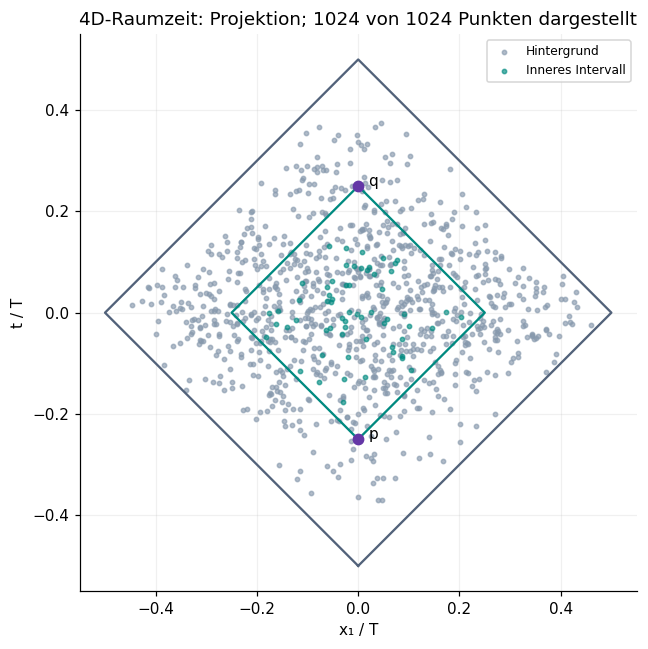

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
shown = np.linspace(0, M-1, min(M, 1400), dtype=int)
for flag, color, title in [(False, '#8799ad', 'Hintergrund'), (True, '#008a80', 'Inneres Intervall')]:
    ids = shown[inside[shown] == flag]
    ax.scatter(points[ids, 1], points[ids, 0], s=8, c=color, alpha=.65, label=title)
for radius, color in [(.5, '#52627a'), (THETA/2, '#008a80')]:
    ax.plot([0, radius, 0, -radius, 0], [-radius, 0, radius, 0, -radius], c=color)
ax.scatter([0, 0], [-THETA/2, THETA/2], c='#6437a6', s=45, zorder=5)
ax.text(.02, -THETA/2, 'p'); ax.text(.02, THETA/2, 'q')
ax.set(xlabel='x₁ / T', ylabel='t / T', aspect='equal',
       title=f'{D}D-Raumzeit: Projektion; {len(shown)} von {M} Punkten dargestellt')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

## 4. Die längste Kette als zusätzliche Ansicht

Für höchstens 256 innere Punkte berechnen wir die längste Kette exakt durch dynamische
Programmierung. $H$ zählt nur innere Knoten; mit $p,q$ wären es $H+2$ Knoten und $H+1$ Kanten.
Es wird hier **keine** asymptotische Kettenkonstante zur endlichen Zeitkalibrierung verwendet.

In [6]:
def longest_chain(inner):
    if len(inner) > 256:
        return None
    ordered = inner[np.argsort(inner[:, 0])]
    heights = np.ones(len(ordered), dtype=int)
    for j in range(len(ordered)):
        delta = ordered[j] - ordered[:j]
        predecessors = (delta[:, 0] > 0) & (delta[:, 0]**2 > np.sum(delta[:, 1:]**2, axis=1))
        if predecessors.any():
            heights[j] = 1 + heights[:j][predecessors].max()
    return int(heights.max()) if len(heights) else 0

H = longest_chain(points[inside])
print('Anzeigegrenze überschritten (K > 256).' if H is None else f'Längste innere Kette: H={H}')

Längste innere Kette: H=5


## 5. Wiederholungen: Deckung ist eine Eigenschaft des Verfahrens

Für Wiederholungen genügt das äquivalente Binomialgesetz. Wir erzeugen keine unnötigen
Raumzeitkoordinaten. Jedes Experiment verwendet dasselbe **vorab feste** Budget $m$.
Der Browser nutzt einen anderen Zufallszahlengenerator; identische Seed-Zahlen erzeugen dort
andere Einzelwolken. Beide Programme verwenden dasselbe mathematische Modell.

Bei diskreten Zählungen kann die tatsächliche Deckung über 95 % liegen. Der beobachtete Anteil
schwankt zusätzlich. Aus 95 % Konfidenz folgt keine nachträgliche Wahrscheinlichkeit für einen
festen Parameter, und auch keine Absicherung beliebig vieler Neustarts oder optionalen Stoppens.

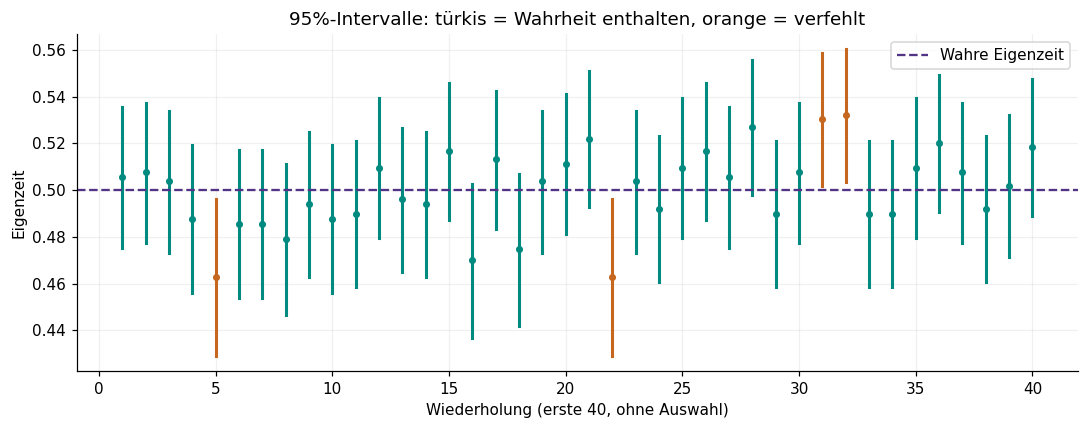

Überdeckung: 1937/2000 = 96.850%
95%-Intervall der Überdeckungsrate: [95.988%, 97.571%]
Theoretische Deckung für diese Parameter: 96.138224%
Beobachteter RMSE/T: 0.015208; exakt: 0.015246
Beobachteter Bias/T: -0.000731


In [7]:
counts = np.random.default_rng(streams[1]).binomial(M, THETA**D, size=REPEATS)
a_low, a_high, theta_low, theta_high = all_limits(M, D, ALPHA)
estimates = T * (counts/M)**(1/D)
covered = (a_low[counts] <= THETA**D) & (THETA**D <= a_high[counts])
errors = estimates/T - THETA
hits = int(covered.sum())
cover_low = 0.0 if hits == 0 else beta.ppf(ALPHA/2, hits, REPEATS-hits+1)
cover_high = 1.0 if hits == REPEATS else beta.ppf(1-ALPHA/2, hits+1, REPEATS-hits)
ks = np.arange(M+1)
mass = binom.pmf(ks, M, THETA**D)
exact_coverage = float(mass[(a_low <= THETA**D) & (THETA**D <= a_high)].sum())
exact_rmse = float(np.sqrt(mass @ (((ks/M)**(1/D)-THETA)**2)))
print(f'Überdeckung: {hits}/{REPEATS} = {hits/REPEATS:.3%}')
print(f'95%-Intervall der Überdeckungsrate: [{cover_low:.3%}, {cover_high:.3%}]')
print(f'Theoretische Deckung für diese Parameter: {exact_coverage:.6%}')
print(f'Beobachteter RMSE/T: {np.sqrt(np.mean(errors**2)):.6f}; exakt: {exact_rmse:.6f}')
print(f'Beobachteter Bias/T: {np.mean(errors):.6f}')
assert abs(mass.sum()-1) < 1e-10
assert exact_coverage >= .95 - 1e-10

fig, ax = plt.subplots(figsize=(10, 4))
for i, k in enumerate(counts[:40]):
    color = '#008a80' if covered[i] else '#c5671e'
    ax.plot([i+1, i+1], [T*theta_low[k], T*theta_high[k]], c=color, lw=2)
    ax.scatter(i+1, estimates[i], c=color, s=13)
ax.axhline(TRUTH, c='#513485', ls='--', label='Wahre Eigenzeit')
ax.set(xlabel='Wiederholung (erste 40, ohne Auswahl)', ylabel='Eigenzeit',
       title='95%-Intervalle: türkis = Wahrheit enthalten, orange = verfehlt')
ax.legend(); plt.tight_layout(); plt.show()

## 6. Auflösung: Wie hilft ein grösseres Budget?

Wir berechnen den Fehler aus einer endlichen Summe über alle möglichen $K$-Werte.
Das ist keine weitere Monte-Carlo-Schätzung. Die Formeln sind exakt; die numerischen Werte
werden mit Gleitkommaarithmetik berechnet.

$$\mathrm{RMSE}/T=\sqrt{\sum_{k=0}^m \Pr(K=k)\big[(k/m)^{1/d}-\theta\big]^2},
\qquad \Pr(K=0)=(1-\theta^d)^m.$$

Bei $d=4$ und $\theta=0.1$ liegt die erwartete innere Punktzahl bei nur $m/10000$.
Ein grösseres Gesamtbudget ist deshalb noch keine Garantie für gute lokale Auflösung.

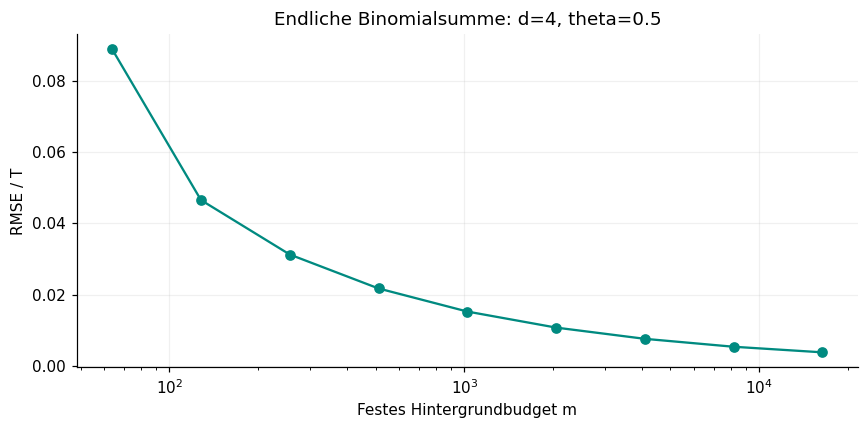

 m       E[K]    P(K=0)    RMSE/T     Bias/T
   64      4.000    0.0161   0.088942  -0.017012
  128      8.000    0.0003   0.046572  -0.006089
  256     16.000    0.0000   0.031276  -0.002865
  512     32.000    0.0000   0.021736  -0.001401
 1024     64.000    0.0000   0.015246  -0.000693
 2048    128.000    0.0000   0.010739  -0.000345
 4096    256.000    0.0000   0.007579  -0.000172
 8192    512.000    0.0000   0.005354  -0.000086
16384   1024.000    0.0000   0.003784  -0.000043


In [8]:
budgets = np.array([64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384])
resolution = []
for m in budgets:
    k = np.arange(m+1)
    pmf = binom.pmf(k, m, THETA**D)
    error = (k/m)**(1/D) - THETA
    resolution.append({'m': int(m), 'rmse': float(np.sqrt(pmf @ (error**2))),
                       'bias': float(pmf @ error), 'expected_k': float(m*THETA**D),
                       'zero_probability': float(np.exp(m*np.log1p(-THETA**D)))})
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(budgets, [r['rmse'] for r in resolution], 'o-', c='#008a80')
ax.set(xscale='log', xlabel='Festes Hintergrundbudget m', ylabel='RMSE / T',
       title=f'Endliche Binomialsumme: d={D}, theta={THETA}')
plt.tight_layout(); plt.show()
print(' m       E[K]    P(K=0)    RMSE/T     Bias/T')
for row in resolution:
    print(f'{row["m"]:5d} {row["expected_k"]:10.3f} {row["zero_probability"]:9.4f}'
          f' {row["rmse"]:10.6f} {row["bias"]:10.6f}')

## 7. Einen exportierten Browserversuch gegenprüfen (optional)

Im Demonstrator **Versuch als JSON** wählen, die Datei neben dieses Notebook legen und unten
`JSON_PATH = "eigenzeit-versuch.json"` setzen. Die Koordinaten sind in Einheiten von $T$ gespeichert.
Wir zählen unabhängig nach und vergleichen die Browsergrenzen mit SciPy.
Diese Gegenprüfung bestätigt Berechnungskonsistenz, nicht die Echtheit physischer Messdaten.

In [9]:
JSON_PATH = ''  # Optional: 'eigenzeit-versuch.json'
if JSON_PATH:
    exported = json.loads(Path(JSON_PATH).read_text(encoding='utf-8'))
    assert exported['schema'] == 'x6.proper-time-lab/1.0'
    p, r = exported['parameters'], exported['result']
    pts = np.asarray(r['points'], dtype=float)
    assert pts.shape == (p['m'], p['d']) and np.isfinite(pts).all()
    assert np.all(np.abs(pts[:, 0]) + np.linalg.norm(pts[:, 1:], axis=1) < .5)
    actual_inside = np.abs(pts[:, 0]) + np.linalg.norm(pts[:, 1:], axis=1) < p['theta']/2
    assert np.array_equal(actual_inside, r['inside'])
    assert int(actual_inside.sum()) == r['k']
    reference = infer(r['k'], p['m'], p['d'], exported['alpha'], p['T'])
    for key in ('estimate', 'lower', 'upper'):
        assert np.isclose(r[key], reference[key], atol=2e-10*p['T'], rtol=2e-10), key
    print('PASS_BROWSER_EXPORT: Koordinaten, Zählung und Zeitgrenzen stimmen überein.')
else:
    print('Optionaler Browservergleich nicht angefordert.')

Optionaler Browservergleich nicht angefordert.


## 8. Was folgt daraus – und was bleibt offen?

- Unter dem deklarierten flachen Stichprobenmodell liefert der Intervallzähler eine statistische Eigenzeitschätzung.
- Ein leeres Intervall liefert eine obere Grenze; es beweist keine verschwindende Eigenzeit.
- Die externe Skala $T$ ist vorgegeben. Die endliche Ordnung allein liefert keine absolute Sekunde.
- Die dargestellte Kette ist keine zusätzliche kalibrierte Uhr und kein Krümmungssensor.
- Unbekannte Dichte, Randabschneidung, falsche Dimension oder abhängige Punkte sind durch dieses Intervall nicht abgesichert.
- Für datenabhängiges Stoppen braucht es die [separate sequenzielle Referenz](https://github.com/thomasmgfeller/x6-spectral-astrolabium/tree/abf1423c985606f5c514ea1bfd2aa48a260ad2bf/research/lorentz_proper_time_sequential).
- Ein Durchlauf und ein Softwaretest sind keine unabhängige wissenschaftliche Replikation.

**English summary:** This standalone notebook illustrates fixed-budget proper-time estimation
in a known flat Minkowski diamond. It uses binomial interval counts and transformed
Clopper–Pearson bounds. Geometry, dimension, sampling law and external time scale are
assumptions. It provides neither an anytime-valid stopping rule nor a curvature detector.

**Provenienz:** Referenzimplementierung `research/lorentz_proper_time_domain/domain.py`,
Repository-Commit `abf1423c985606f5c514ea1bfd2aa48a260ad2bf`. Das Notebook ist eine
selbständige, numerisch gegengeprüfte Erläuterung; es verändert die ursprünglichen Ergebnisarchive nicht.
Lizenz des Codes: Apache-2.0.